# TP3 - CNN´s en Imagenes Satelitales

> Utilizaremos el dataset EuroSAT para entrenar un modelo de redes neuronales convulacionales. La idea principal es identifiar distintos tipos del uso del suelo vía imagenes.

> Para crear el modelo de CNN´s utilizaremos la biblioteca *PyTorch*. Esta biblioteca es de aprendizaje automatico y deep learning. Podemos crear tensores, diferenciación automatica y construir redes neuronales.

In [15]:
# Bibliotecas

import pandas as pd
import torch
import os # Para ver la ruta del archivo con los datos.

DATA_DIR = "EuroSAT" # Directorio donde se encuentran los datos.

#### 1- Analizamos un análisis explotario de los datos (EDA). 

> Lo realizamos para mirar y entender los datos antes de modelar. Sin entrenar podemos hacernos preguntas sobre el dataset. 

> Podemos detectar problemas antes de entrenar, tomar decisiones de preprocesamiento y anticipar resultados.

In [16]:
datos_train = os.path.join(DATA_DIR, "train.csv")
datos_validation = os.path.join(DATA_DIR, "validation.csv")
datos_test = os.path.join(DATA_DIR, "test.csv")

train_df = pd.read_csv(datos_train)
validation_df = pd.read_csv(datos_validation)
test_df = pd.read_csv(datos_test)

In [17]:
train_df.head(5)

,Unnamed: 0,Filename,Label,ClassName
0,16257,AnnualCrop/AnnualCrop_142.jpg,0,AnnualCrop
1,3297,HerbaceousVegetation/HerbaceousVegetation_2835...,2,HerbaceousVegetation
2,17881,PermanentCrop/PermanentCrop_1073.jpg,6,PermanentCrop
3,2223,Industrial/Industrial_453.jpg,4,Industrial
4,4887,HerbaceousVegetation/HerbaceousVegetation_1810...,2,HerbaceousVegetation


In [18]:
validation_df.head(5)

,Unnamed: 0,Filename,Label,ClassName
0,258,Pasture/Pasture_1481.jpg,5,Pasture
1,2134,Forest/Forest_2638.jpg,1,Forest
2,3518,Highway/Highway_875.jpg,3,Highway
3,3048,River/River_434.jpg,8,River
4,3996,SeaLake/SeaLake_2930.jpg,9,SeaLake


In [19]:
test_df.head(5)

,Unnamed: 0,Filename,Label,ClassName
0,2438,AnnualCrop/AnnualCrop_1275.jpg,0,AnnualCrop
1,1018,Residential/Residential_504.jpg,7,Residential
2,3,Pasture/Pasture_787.jpg,5,Pasture
3,1011,Residential/Residential_1575.jpg,7,Residential
4,47,Pasture/Pasture_473.jpg,5,Pasture


In [ ]:
# Limpieza de datos:
# Descartamos la primera columna que no aporta valor alguno. Solamente es el indice que tenia en la fila en el dataset original.

test_df = test_df.drop(columns=["Unnamed: 0"])

validation_df = validation_df.drop(columns=["Unnamed: 0"])

train_df = train_df.drop(columns=["Unnamed: 0"])

,Filename,Label,ClassName
0,AnnualCrop/AnnualCrop_1275.jpg,0,AnnualCrop
1,Residential/Residential_504.jpg,7,Residential
2,Pasture/Pasture_787.jpg,5,Pasture
3,Residential/Residential_1575.jpg,7,Residential
4,Pasture/Pasture_473.jpg,5,Pasture


In [ ]:
# Tamaño de los datasets:

test_df.shape[0]

2700

In [23]:
validation_df.shape[0]

5400

In [24]:
train_df.shape[0]

18900

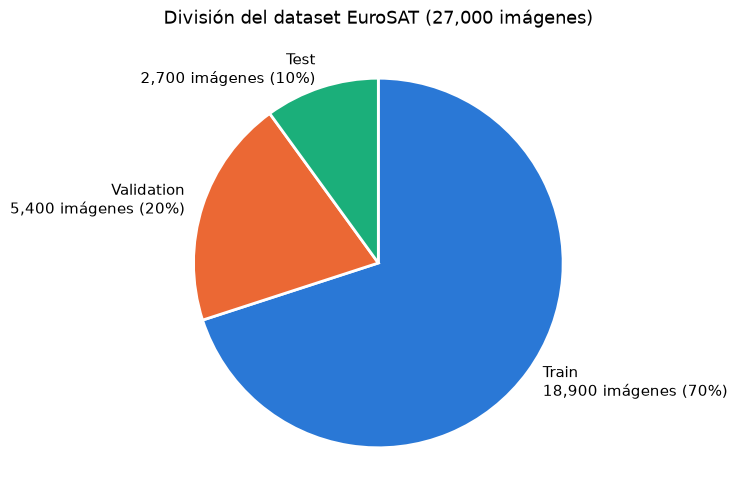

In [25]:
import matplotlib.pyplot as plt

# 1) Datos: nombre y cantidad de imágenes de cada split
nombres = ["Train", "Validation", "Test"]
tamaños = [len(train_df), len(validation_df), len(test_df)]  # len() = cantidad de filas
total = sum(tamaños)

# 2) Etiquetas con nombre, cantidad y porcentaje
etiquetas = [
    f"{nombre}\n{tamaño:,} imágenes ({tamaño / total:.0%})"
    for nombre, tamaño in zip(nombres, tamaños)
]

# 3) Gráfico de torta
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    tamaños,
    labels=etiquetas,
    colors=["#2a78d6", "#eb6834", "#1baf7a"],     # un color distinto por split
    startangle=90,                                # arranca desde arriba
    counterclock=False,                           # gira en sentido horario
    wedgeprops={"edgecolor": "white", "linewidth": 2},  # separa las porciones
    textprops={"fontsize": 11},
)
ax.set_title(f"División del dataset EuroSAT ({total:,} imágenes)", fontsize=13)
plt.show()


> Como vemos, la división de datasets esta en formato estandar de simple holdout set + validation y tenemos imagenes de mas como para entrenar, validar y testear el modelo.

> ¿Las clases estan balanceadas?


<Axes: >

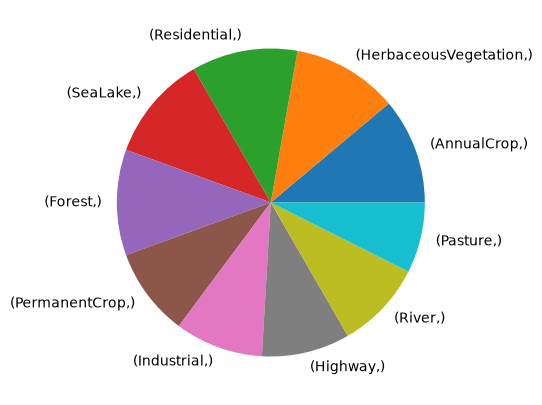

In [29]:
train_df.value_counts(["ClassName"]).plot(kind="pie", figsize=(10, 5), color="#2a78d6")

<Axes: >

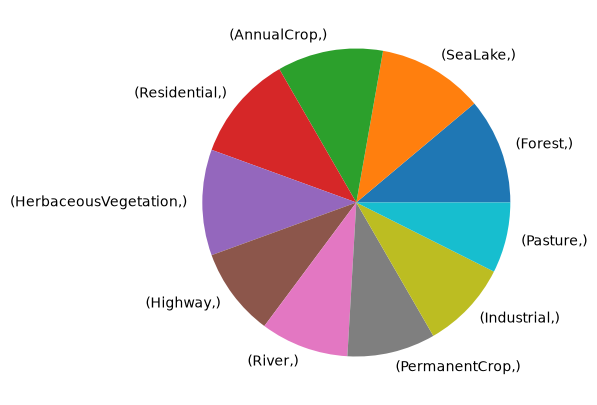

In [30]:
validation_df.value_counts(["ClassName"]).plot(kind="pie", figsize=(10, 5), color="#2a78d6")

<Axes: >

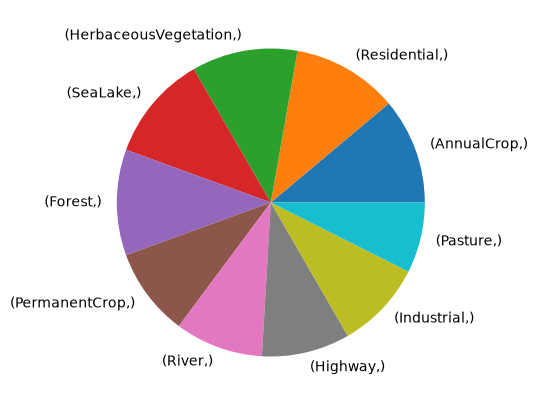

In [31]:
test_df.value_counts(["ClassName"]).plot(kind="pie", figsize=(10, 5), color="#2a78d6")